# Create stickman image

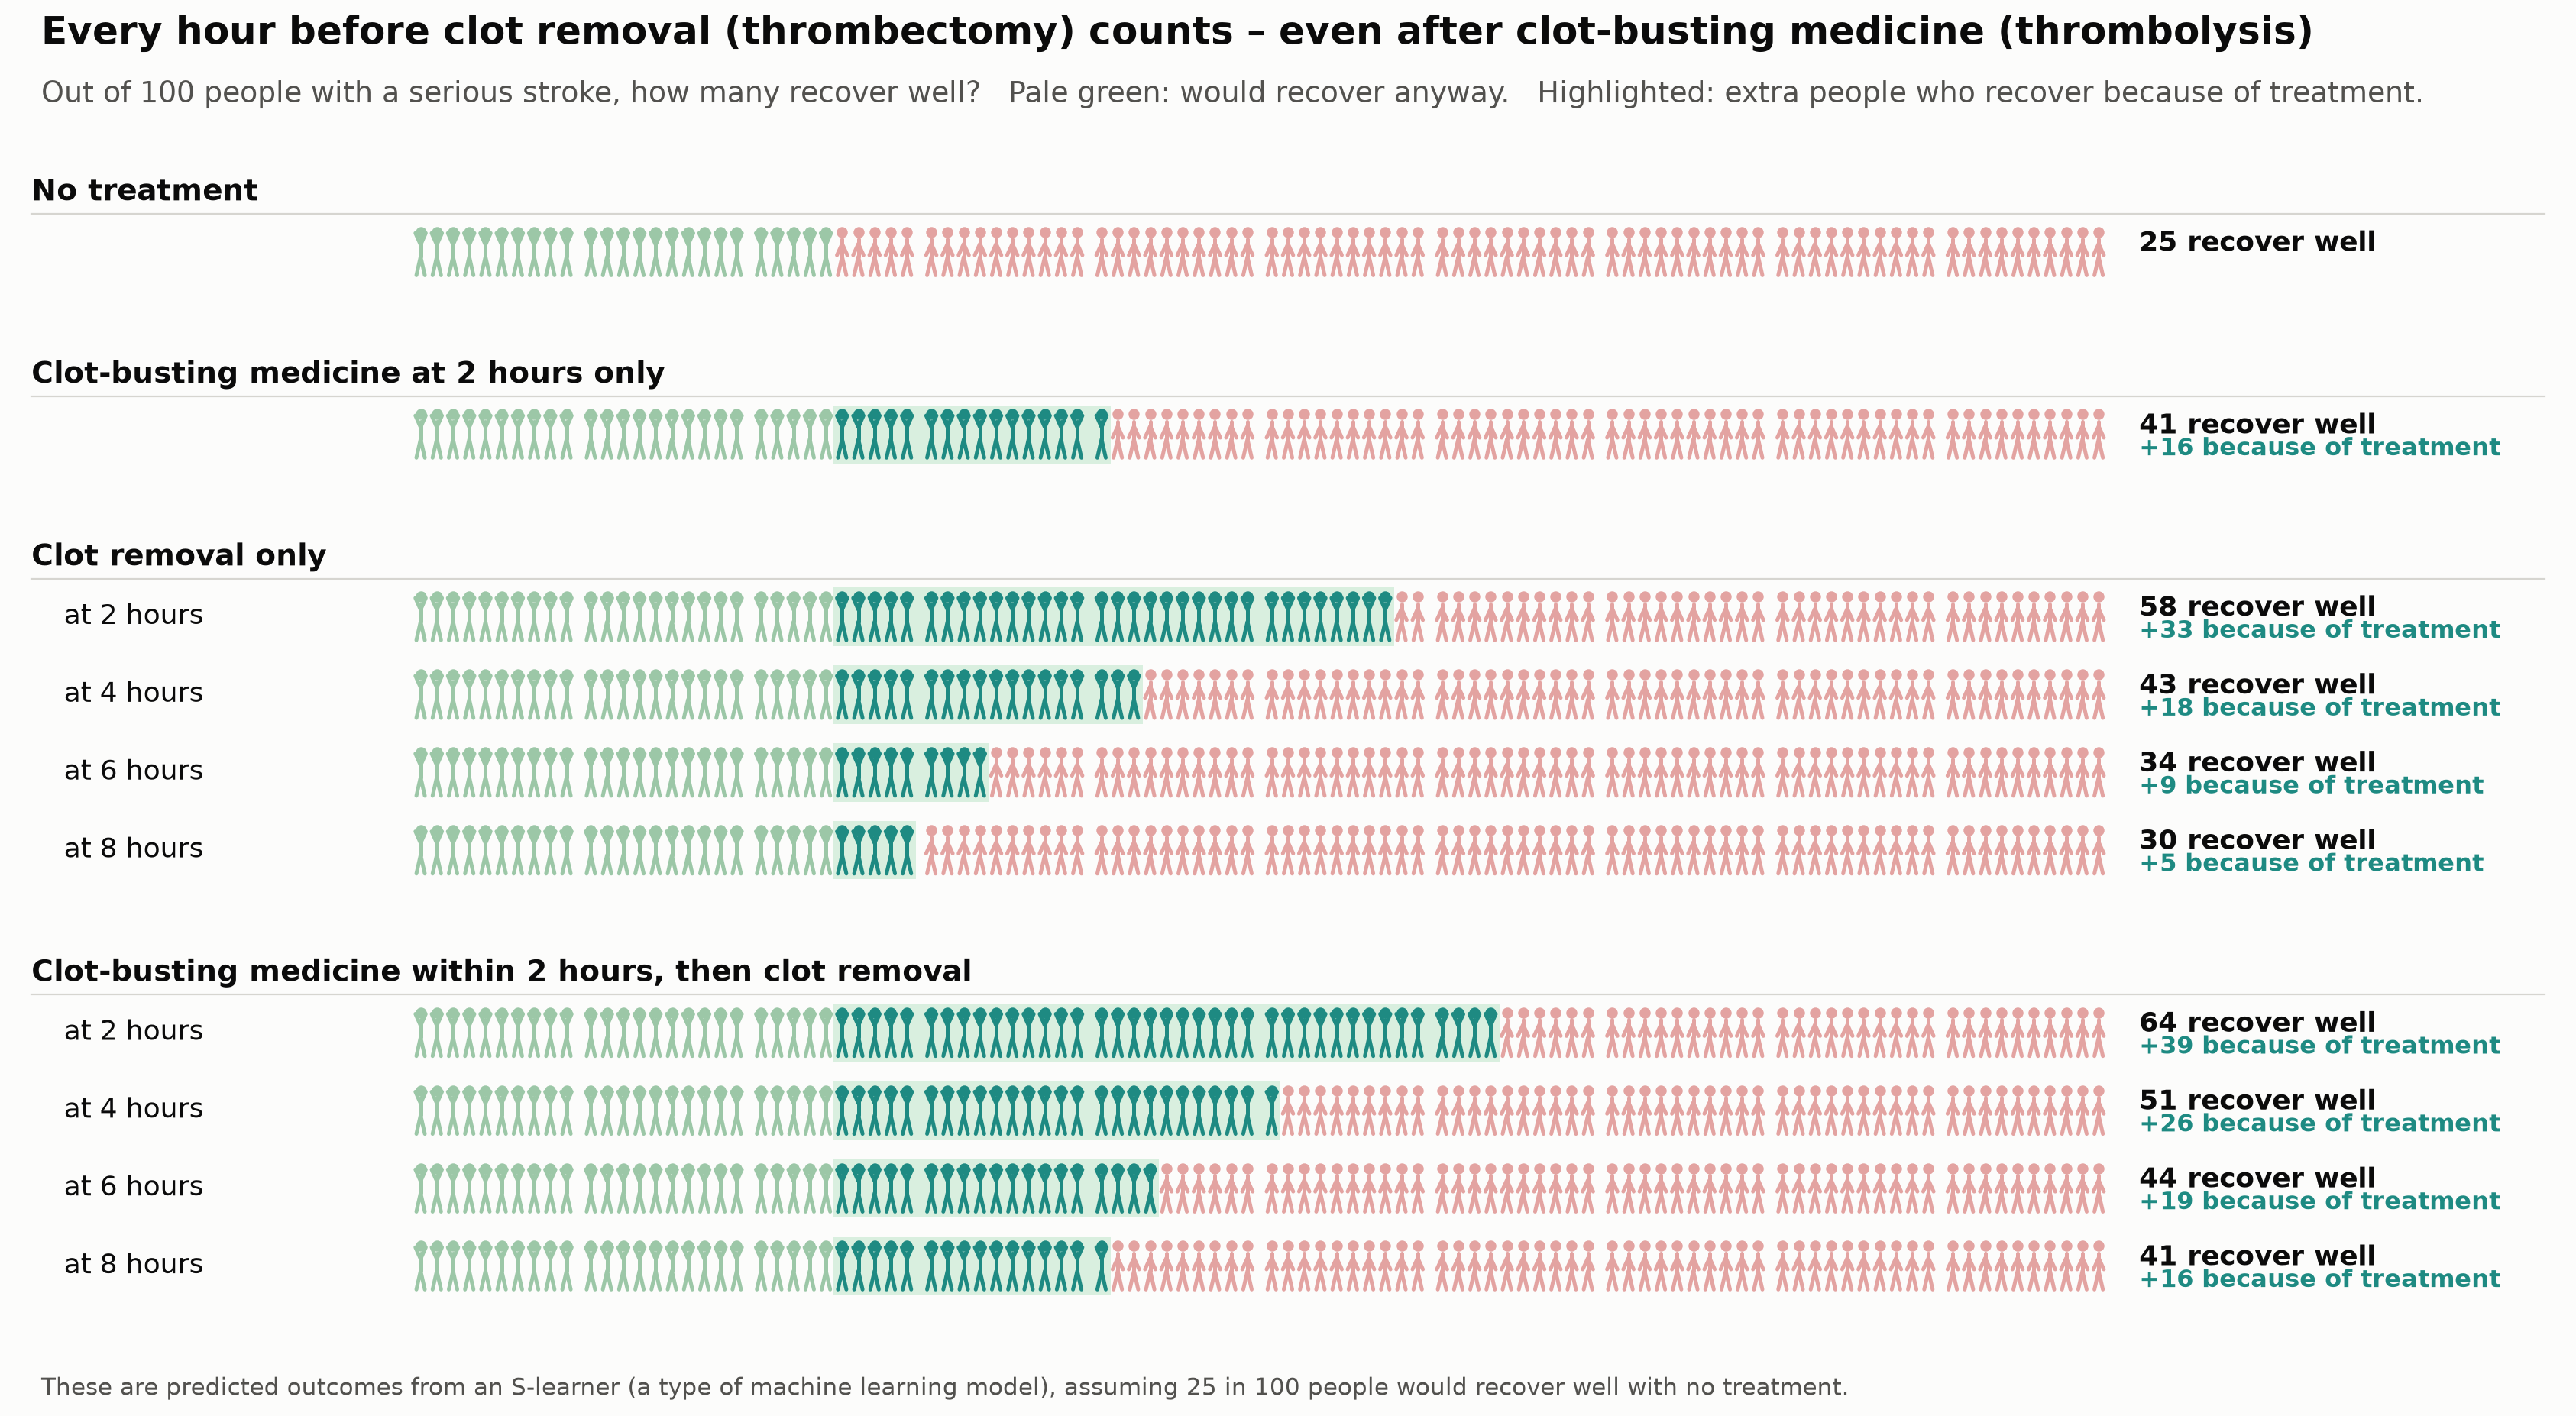

In [1]:
"""Each scenario as one horizontal line of 100 people (green = recovers well).

logit(p) = logit(BASELINE) + net benefit (log odds ratio, read by eye from the S-learner figure).
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

BASELINE = 0.25
IVT_ONLY = 0.74   # log OR, IVT at 2 h without thrombectomy (interpolated from 60-120 and 120-180 bins)
LOR = {"none": {2: 1.43, 4: 0.81, 6: 0.43, 8: 0.27, 10: 0.10},
       "ivt":  {2: 1.66, 4: 1.13, 6: 0.85, 8: 0.73, 10: 0.70}}

GOOD, BAD = "#1e8a82", "#e3a3a1"
ANYWAY, HILITE = "#9cc7a7", "#d9efdf"
INK, MUTED, SURF, RULE = "#0b0b0b", "#52514e", "#fcfcfb", "#d6d5d0"


def n_good(lor):
    lo = np.log(BASELINE / (1 - BASELINE)) + lor
    return int(round(100 / (1 + np.exp(-lo))))


VS = 2.0  # vertical stretch of each figure


def stickman(ax, x, y, good, c=None):
    c = c or (GOOD if good else BAD)
    lw = 1.8
    ax.plot(x, y + 0.62 * VS, "o", ms=5.2, color=c, mew=0)
    ax.plot([x, x], [y + 0.40 * VS, y - 0.15 * VS], color=c, lw=lw, solid_capstyle="round")
    arms = [y + 0.58 * VS, y + 0.22 * VS, y + 0.58 * VS] if good else [y - 0.10 * VS, y + 0.25 * VS, y - 0.10 * VS]
    ax.plot([x - 0.32, x, x + 0.32], arms, color=c, lw=lw, solid_capstyle="round")
    ax.plot([x - 0.26, x, x + 0.26], [y - 0.72 * VS, y - 0.15 * VS, y - 0.72 * VS], color=c, lw=lw,
            solid_capstyle="round")


# (group header or None, row label, n good)
BASE_N = n_good(0.0)
rows = [("No treatment", "", n_good(0.0)),
        ("Clot-busting medicine at 2 hours only", "", n_good(IVT_ONLY))]
for key, head in [("none", "Clot removal only"), ("ivt", "Clot-busting medicine within 2 hours, then clot removal")]:
    for i, t in enumerate([2, 4, 6, 8]):
        rows.append((head if i == 0 else None, f"at {t} hours", n_good(LOR[key][t])))

ROW_H, HEAD_H = 2.4 * VS, 1.5 * VS
X0 = 0          # first figure x
fig, ax = plt.subplots(figsize=(17, 6), dpi=200, facecolor=SURF)
ax.set_facecolor(SURF); ax.axis("off")

y = 0
for head, lab, k in rows:
    if head:
        y -= HEAD_H if y else 1.0 * VS
        ax.text(-24, y + 0.1 * VS, head, fontsize=14, fontweight="bold", color=INK, va="center")
        ax.plot([-24, 131], [y - 0.55 * VS] * 2, color=RULE, lw=0.8)
        y -= ROW_H * 0.72
    xpos = lambda i: X0 + i + 0.5 * (i // 10)   # small gap every 10 people to help counting
    if k > BASE_N:   # highlight the extra people who recover because of treatment
        ax.add_patch(Rectangle((xpos(BASE_N) - 0.55, y - 0.9 * VS), xpos(k - 1) - xpos(BASE_N) + 1.1,
                               1.8 * VS, color=HILITE, lw=0, zorder=0))
    for i in range(100):
        col = ANYWAY if i < BASE_N else (GOOD if i < k else BAD)
        stickman(ax, xpos(i), y, i < k, col)
    ax.text(-22, y, lab, fontsize=13, color=INK, va="center")
    ax.text(106, y + 0.25 * VS, f"{k} recover well", fontsize=13, fontweight="bold", color=INK,
            va="center", ha="left")
    if k > BASE_N:
        ax.text(106, y - 0.45 * VS, f"+{k - BASE_N} because of treatment", fontsize=11.5,
                color=GOOD, fontweight="bold", va="center", ha="left")
    y -= ROW_H

XL, XR, YT, YB = -25, 132, 0.0, y - 0.3 * VS
ax.set_xlim(XL, XR); ax.set_ylim(YB, YT)
W = 17; plot_h = W * 0.98 * (YT - YB) / (XR - XL)
FOOT = 0.45
fig.set_size_inches(W, plot_h + 1.3 + FOOT)
top = (plot_h + FOOT) / (plot_h + 1.3 + FOOT)
fig.text(0.02, 1 - 0.45 / (plot_h + 1.3 + FOOT), "Every hour before clot removal (thrombectomy) counts – even after clot-busting medicine (thrombolysis)",
         fontsize=18, fontweight="bold", color=INK, va="center")
fig.text(0.02, 1 - 0.85 / (plot_h + 1.3 + FOOT), "Out of 100 people with a serious stroke, how many recover well?   Pale green: would recover anyway.   "
         "Highlighted: extra people who recover because of treatment.",
         fontsize=13.5, color=MUTED, va="center")
ax.set_position([0.01, FOOT / (plot_h + 1.3 + FOOT), 0.98, top - FOOT / (plot_h + 1.3 + FOOT)])
fig.text(0.02, 0.22 / (plot_h + 1.3 + FOOT),
         "These are predicted outcomes from an S-learner (a type of machine learning model), "
         f"assuming {int(BASELINE * 100)} in 100 people would recover well with no treatment.",
         fontsize=11, color=MUTED, va="center") 
fig.savefig("stickmen_rows.png", facecolor=SURF)
#fig.savefig("stickmen_rows.svg", facecolor=SURF)

plt.show()